# Proyek Analisis Data: E-Commerce Public Dataset

- **Nama:** Adam Himawan
- **Email:** ds009b6y0030@student.devacademy.id
- **ID Dicoding:** ds009b6y0030

Notebook ini menganalisis **E-Commerce Public Dataset** (data transaksi marketplace Olist, Brasil) untuk memahami performa penjualan, kategori produk unggulan, pengaruh ketepatan pengiriman terhadap kepuasan pelanggan, serta segmentasi pelanggan dan persebaran geografisnya.

**Periode analisis:** 1 Januari 2017 – 31 Agustus 2018 (20 bulan penuh). Data September–Desember 2016 dan September–Oktober 2018 tidak dipakai karena jumlah pesanannya sangat sedikit (data belum/tidak lengkap) sehingga bisa menyesatkan tren.

**Definisi revenue:** total `price` pada `order_items` untuk pesanan berstatus `delivered` (nilai barang yang benar-benar sampai ke pelanggan, tanpa ongkos kirim). Satuan mata uang: Real Brasil (R$).

## Menentukan Pertanyaan Bisnis

Ketiga pertanyaan berikut disusun dengan kerangka **SMART** (Specific, Measurable, Action-oriented, Relevant, Time-bound):

- **Pertanyaan 1 – Tren penjualan:** Bagaimana tren jumlah pesanan dan revenue bulanan selama Januari 2017 – Agustus 2018, bulan apa yang mencatat revenue tertinggi, dan berapa persen pertumbuhan revenue Januari–Agustus 2018 dibandingkan Januari–Agustus 2017?
- **Pertanyaan 2 – Kategori produk:** Kategori produk apa saja yang termasuk 10 besar penyumbang revenue selama Januari 2017 – Agustus 2018, berapa persen kontribusi gabungannya terhadap total revenue, dan kategori mana yang revenue-nya paling kecil?
- **Pertanyaan 3 – Pengiriman & kepuasan:** Seberapa besar selisih rata-rata *review score* antara pesanan yang terlambat dan yang tepat waktu selama Januari 2017 – Agustus 2018, dan bagaimana rata-rata skor tersebut berubah menurut lamanya keterlambatan (dalam hari)?

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| **Specific** | Fokus pada jumlah pesanan & revenue per bulan | Fokus pada revenue per kategori produk | Fokus pada keterlambatan vs *review score* |
| **Measurable** | Jumlah pesanan, revenue (R$), % pertumbuhan YoY | Revenue (R$), % kontribusi 10 besar | Rata-rata skor (1–5), selisih skor, % ulasan buruk |
| **Action-oriented** | Menentukan waktu kampanye & kesiapan kapasitas | Menentukan prioritas stok & promosi | Menentukan perbaikan SLA logistik & estimasi pengiriman |
| **Relevant** | Pertumbuhan penjualan adalah KPI utama marketplace | Fokus sumber daya pada kategori bernilai tinggi | Kepuasan pelanggan memengaruhi retensi & reputasi |
| **Time-bound** | Jan 2017 – Ags 2018 | Jan 2017 – Ags 2018 | Jan 2017 – Ags 2018 |

Selain itu, bagian **Analisis Lanjutan** melengkapi jawaban dengan **RFM Analysis**, **Geospatial Analysis**, dan **Clustering** (manual grouping & binning) tanpa algoritma machine learning.

## Import Semua Packages/Library yang Digunakan

In [1]:
import json
import os
import unicodedata
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Polygon
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Gaya visual yang konsisten di seluruh notebook
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#d9d8d3",
    "grid.color": "#ecebe7",
    "axes.titlelocation": "left",
})

# Palet: satu warna utama untuk satu seri data, abu-abu untuk konteks, oranye untuk penekanan
MAIN = "#2a78d6"     # biru utama
ACCENT = "#eb6834"   # oranye penekanan
GREY = "#c9c8c2"     # abu-abu konteks
TEXT = "#52514e"     # warna teks sekunder

# Dataset dibaca dari folder lokal "data/" jika tersedia. Jika tidak ada (misalnya
# karena batas ukuran upload submission), dataset otomatis diambil dari repositori GitHub.
LOCAL_DATA_DIR = "data/"
REMOTE_DATA_DIR = "https://raw.githubusercontent.com/Mudzip/proyek-analisis-data-ecommerce/main/data/"
DATA_DIR = LOCAL_DATA_DIR if os.path.exists(LOCAL_DATA_DIR + "orders_dataset.csv") else REMOTE_DATA_DIR
print("Sumber data:", DATA_DIR)

START_DATE = pd.Timestamp("2017-01-01")
END_DATE = pd.Timestamp("2018-08-31 23:59:59")

def rupiah_brl(x, pos=None):
    """Format sumbu dalam satuan ribu Real Brasil."""
    return f"R${x/1_000:,.0f}K"

Sumber data: data/


## Data Wrangling
### Gathering Data

Dataset terdiri dari 9 tabel CSV yang saling terhubung melalui kunci `order_id`, `customer_id`, `product_id`, `seller_id`, dan `zip_code_prefix`. Kolom kode pos dibaca sebagai **string** agar angka nol di depan (misalnya `01037`) tidak hilang.

> Catatan: file CSV dibaca dari folder `data/`. Karena ukuran dataset melebihi batas upload submission (25 MB), folder tersebut tidak disertakan di berkas zip. Jika folder `data/` tidak ditemukan, notebook otomatis membaca dataset yang sama dari [repositori GitHub proyek ini](https://github.com/Mudzip/proyek-analisis-data-ecommerce/tree/main/data).

In [2]:
zip_str = {
    "customer_zip_code_prefix": str,
    "seller_zip_code_prefix": str,
    "geolocation_zip_code_prefix": str,
}

customers_df = pd.read_csv(DATA_DIR + "customers_dataset.csv", dtype=zip_str)
geolocation_df = pd.read_csv(DATA_DIR + "geolocation_dataset.csv", dtype=zip_str)
orders_df = pd.read_csv(DATA_DIR + "orders_dataset.csv")
order_items_df = pd.read_csv(DATA_DIR + "order_items_dataset.csv")
order_payments_df = pd.read_csv(DATA_DIR + "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(DATA_DIR + "order_reviews_dataset.csv")
products_df = pd.read_csv(DATA_DIR + "products_dataset.csv")
category_translation_df = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")
sellers_df = pd.read_csv(DATA_DIR + "sellers_dataset.csv", dtype=zip_str)

tables = {
    "customers": customers_df,
    "geolocation": geolocation_df,
    "orders": orders_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "products": products_df,
    "category_translation": category_translation_df,
    "sellers": sellers_df,
}
for name, df in tables.items():
    print(f"{name:<22} {df.shape[0]:>9,} baris x {df.shape[1]} kolom")

customers                 99,441 baris x 5 kolom
geolocation            1,000,163 baris x 5 kolom
orders                    99,441 baris x 8 kolom
order_items              112,650 baris x 7 kolom
order_payments           103,886 baris x 5 kolom
order_reviews             99,224 baris x 7 kolom
products                  32,951 baris x 9 kolom
category_translation          71 baris x 2 kolom
sellers                    3,095 baris x 4 kolom


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [5]:
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


In [7]:
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


**Insight:**
- Dataset terdiri dari 9 tabel. Tabel terbesar adalah `geolocation` (±1 juta baris), sedangkan tabel inti transaksi adalah `orders` (99.441 pesanan) dan `order_items` (112.650 item).
- Satu pesanan bisa berisi beberapa item (`order_item_id`), sehingga revenue dihitung dari `order_items`, bukan dari `orders`.
- Tabel `customers` memiliki dua identitas: `customer_id` (berbeda di setiap pesanan) dan `customer_unique_id` (identitas pelanggan sebenarnya). Perbedaan ini penting untuk analisis pelanggan dan RFM.
- Tabel dihubungkan melalui kunci `order_id`, `customer_id`, `product_id`, dan kode pos, sehingga semua tabel bisa digabung menjadi satu data analisis.

### Assessing Data

Penilaian dilakukan dua lapis: (1) ringkasan cepat semua tabel (jumlah missing value dan baris duplikat), lalu (2) pemeriksaan mendalam per tabel untuk tipe data yang keliru, nilai tidak valid, inkonsistensi, dan outlier.

In [8]:
overview = pd.DataFrame({
    "jumlah_baris": {n: d.shape[0] for n, d in tables.items()},
    "total_missing": {n: int(d.isna().sum().sum()) for n, d in tables.items()},
    "baris_duplikat": {n: int(d.duplicated().sum()) for n, d in tables.items()},
})
overview

,jumlah_baris,total_missing,baris_duplikat
customers,99441,0,0
geolocation,1000163,0,261831
orders,99441,4908,0
order_items,112650,0,0
order_payments,103886,0,0
order_reviews,99224,145903,0
products,32951,2448,0
category_translation,71,0,0
sellers,3095,0,0


#### Menilai tabel `orders`

In [9]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [10]:
print("Missing value per kolom:")
print(orders_df.isna().sum())
print("\nDistribusi status pesanan:")
print(orders_df["order_status"].value_counts())

Missing value per kolom:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [11]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
tmp = orders_df[date_cols].apply(pd.to_datetime)

delivered_mask = orders_df["order_status"] == "delivered"
print("Pesanan 'delivered' tanpa tanggal diterima pelanggan :",
      tmp.loc[delivered_mask, "order_delivered_customer_date"].isna().sum())
print("Pesanan selain 'delivered' tapi punya tanggal diterima :",
      tmp.loc[~delivered_mask, "order_delivered_customer_date"].notna().sum())
print("Tanggal serah ke kurir < tanggal pembelian           :",
      (tmp["order_delivered_carrier_date"] < tmp["order_purchase_timestamp"]).sum())
print("Tanggal diterima pelanggan < tanggal serah ke kurir  :",
      (tmp["order_delivered_customer_date"] < tmp["order_delivered_carrier_date"]).sum())

Pesanan 'delivered' tanpa tanggal diterima pelanggan : 8
Pesanan selain 'delivered' tapi punya tanggal diterima : 6
Tanggal serah ke kurir < tanggal pembelian           : 166
Tanggal diterima pelanggan < tanggal serah ke kurir  : 23


In [12]:
# Jumlah pesanan per bulan untuk menilai kelengkapan periode data
orders_per_month = tmp["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
print(orders_per_month.to_string())

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


#### Menilai tabel `order_items`

In [13]:
order_items_df.info()
print("\nDuplikat baris:", order_items_df.duplicated().sum())
order_items_df[["price", "freight_value"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB

Duplikat baris: 0


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


In [14]:
def count_iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum()), lower, upper

for col in ["price", "freight_value"]:
    n_out, lower, upper = count_iqr_outliers(order_items_df[col])
    print(f"{col:<14}: {n_out:,} outlier ({n_out / len(order_items_df):.1%}), batas IQR [{lower:,.2f} ; {upper:,.2f}]")

price         : 8,427 outlier (7.5%), batas IQR [-102.60 ; 277.40]
freight_value : 12,134 outlier (10.8%), batas IQR [0.98 ; 33.25]


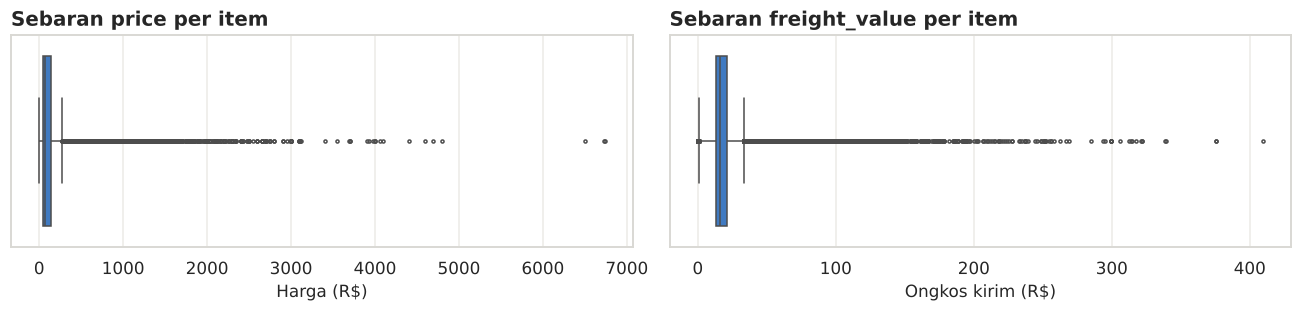

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=order_items_df["price"], ax=axes[0], color=MAIN, fliersize=2)
axes[0].set_title("Sebaran price per item")
axes[0].set_xlabel("Harga (R$)")
sns.boxplot(x=order_items_df["freight_value"], ax=axes[1], color=MAIN, fliersize=2)
axes[1].set_title("Sebaran freight_value per item")
axes[1].set_xlabel("Ongkos kirim (R$)")
plt.tight_layout()
plt.show()

#### Menilai tabel `order_payments`

In [16]:
order_payments_df.info()
print("\nJenis pembayaran:")
print(order_payments_df["payment_type"].value_counts())
print("\nPembayaran bernilai 0      :", (order_payments_df["payment_value"] == 0).sum())
print("Cicilan (installments) = 0 :", (order_payments_df["payment_installments"] == 0).sum())
order_payments_df[order_payments_df["payment_type"] == "not_defined"]

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB

Jenis pembayaran:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Pembayaran bernilai 0      : 9
Cicilan (installments) = 0 : 2


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


#### Menilai tabel `order_reviews`

In [17]:
order_reviews_df.info()
print("\nMissing value per kolom:")
print(order_reviews_df.isna().sum())
print("\nreview_id duplikat           :", order_reviews_df["review_id"].duplicated().sum())
print("order_id dengan >1 ulasan     :", order_reviews_df["order_id"].duplicated().sum())
print("\nDistribusi review_score:")
print(order_reviews_df["review_score"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB

Missing value per kolom:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

review_id duplikat           : 814
order_id dengan >1 ulasan     : 551

Distribusi review_score:
review_score
1    11

#### Menilai tabel `products` dan `category_translation`

In [18]:
products_df.info()
print("\nMissing value per kolom:")
print(products_df.isna().sum())
print("\nProduk dengan berat 0 gram:", (products_df["product_weight_g"] == 0).sum())

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB

Missing value per kolom:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                

In [19]:
untranslated = set(products_df["product_category_name"].dropna()) - set(category_translation_df["product_category_name"])
print("Kategori tanpa terjemahan bahasa Inggris:", untranslated)

Kategori tanpa terjemahan bahasa Inggris: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


#### Menilai tabel `customers`

In [20]:
customers_df.info()
print("\nDuplikat baris            :", customers_df.duplicated().sum())
print("customer_id unik           :", customers_df["customer_id"].nunique())
print("customer_unique_id unik    :", customers_df["customer_unique_id"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  str  
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: str(5)
memory usage: 11.5 MB

Duplikat baris            : 0
customer_id unik           : 99441
customer_unique_id unik    : 96096


#### Menilai tabel `geolocation`

In [21]:
geolocation_df.info()
print("\nBaris duplikat              :", geolocation_df.duplicated().sum())
print("Kode pos unik               :", geolocation_df["geolocation_zip_code_prefix"].nunique())

# Batas kotak (bounding box) wilayah Brasil
outside_brazil = (
    (geolocation_df["geolocation_lat"] > 5.27) | (geolocation_df["geolocation_lat"] < -33.75)
    | (geolocation_df["geolocation_lng"] > -34.79) | (geolocation_df["geolocation_lng"] < -73.99)
)
print("Koordinat di luar wilayah Brasil:", outside_brazil.sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  str    
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), str(3)
memory usage: 54.9 MB



Baris duplikat              : 261831
Kode pos unik               : 19015
Koordinat di luar wilayah Brasil: 42


In [22]:
# Inkonsistensi penulisan nama kota (dengan/tanpa aksen)
geolocation_df.loc[geolocation_df["geolocation_city"].str.contains("paulo"), "geolocation_city"].value_counts().head(4)

geolocation_city
sao paulo                      135800
são paulo                       24918
paulo afonso                      434
engenheiro paulo de frontin        81
Name: count, dtype: int64

#### Menilai tabel `sellers`

In [23]:
sellers_df.info()
print("\nDuplikat baris:", sellers_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   str  
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: str(4)
memory usage: 245.5 KB

Duplikat baris: 0


**Insight:** ringkasan masalah yang ditemukan dan rencana pembersihannya.

| Tabel | Masalah | Jenis masalah | Tindakan di tahap Cleaning |
|---|---|---|---|
| `orders` | 5 kolom tanggal bertipe teks (`object`/`str`) | Tipe data tidak valid | Ubah ke `datetime` |
| `orders` | Missing value: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), `order_delivered_customer_date` (2.965) | Missing value | Dibiarkan karena wajar untuk pesanan batal/belum sampai; 8 pesanan `delivered` tanpa tanggal diterima dikeluarkan dari analisis pengiriman |
| `orders` | 166 tanggal serah ke kurir lebih awal dari tanggal pembelian | Inaccurate value | Diubah menjadi `NaT` |
| `orders` | Pesanan Sep–Des 2016 dan Sep–Okt 2018 sangat sedikit (1–324 per bulan) | Data tidak lengkap | Analisis dibatasi Jan 2017 – Ags 2018 |
| `order_items` | `shipping_limit_date` bertipe teks; outlier `price` 8.427 baris (7,5%) dan `freight_value` 12.134 baris (10,8%) | Tipe data & outlier | Ubah ke `datetime`; outlier dicek kewajarannya lalu dipertahankan |
| `order_payments` | 3 baris `payment_type = not_defined` bernilai 0 dan 2 baris cicilan 0 | Invalid value | Hapus `not_defined`, ubah cicilan 0 → 1 |
| `order_reviews` | 814 `review_id` duplikat dan 551 pesanan memiliki >1 ulasan | Duplicate data | Hapus duplikat, simpan ulasan terbaru per pesanan |
| `order_reviews` | Judul (87.656) dan isi komentar (58.247) kosong | Missing value | Dibiarkan karena komentar bersifat opsional |
| `products` | 610 kategori kosong, 2 dimensi kosong, 4 berat 0 gram, salah ketik `lenght` | Missing, invalid, inconsistent | Isi `unknown`/median kategori, perbaiki nama kolom |
| `category_translation` | 2 kategori belum punya terjemahan | Inconsistent value | Tambahkan terjemahan manual |
| `geolocation` | 261.831 baris duplikat, 42 koordinat di luar Brasil, nama kota tidak seragam (`sao paulo` vs `são paulo`), satu kode pos punya banyak koordinat | Duplicate, inaccurate, inconsistent | Hapus duplikat & koordinat luar Brasil, seragamkan nama kota, ringkas ke median per kode pos |
| `customers`, `sellers` | Tidak ada missing value maupun duplikat | – | Tidak perlu dibersihkan |

### Cleaning Data

Pembersihan dilakukan sesuai temuan di tahap Assessing, tabel demi tabel. Prinsipnya: **perbaiki tipe & nilai yang salah, buang yang tidak bisa diperbaiki, dan pertahankan transaksi yang valid** (termasuk outlier harga yang memang wajar).

#### Membersihkan tabel `orders`
1. Mengubah 5 kolom tanggal dari `object` menjadi `datetime`.
2. Mengosongkan (`NaT`) tanggal serah-ke-kurir yang lebih awal dari tanggal pembelian (nilai tidak akurat). Kolom ini tidak dipakai untuk perhitungan, jadi barisnya tetap dipertahankan.
3. Missing value pada tanggal approval/pengiriman **tidak diisi** karena wajar terjadi pada pesanan yang batal, belum dikirim, atau belum sampai. Pesanan `delivered` tanpa tanggal diterima akan dikeluarkan khusus dari analisis pengiriman.

In [24]:
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

invalid_carrier = orders_df["order_delivered_carrier_date"] < orders_df["order_purchase_timestamp"]
orders_df.loc[invalid_carrier, "order_delivered_carrier_date"] = pd.NaT

print(orders_df[date_cols].dtypes)
print("\nTanggal kurir tidak akurat yang tersisa:",
      (orders_df["order_delivered_carrier_date"] < orders_df["order_purchase_timestamp"]).sum())

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Tanggal kurir tidak akurat yang tersisa: 0


#### Membersihkan tabel `order_items`
Kolom `shipping_limit_date` diubah ke `datetime`. Outlier pada `price` dan `freight_value` **tidak dihapus**: harga tinggi berasal dari produk yang memang mahal (lihat tabel di bawah), sehingga menghapusnya justru menghilangkan revenue yang nyata. Untuk menggambarkan nilai "tipikal", analisis selanjutnya menggunakan median selain rata-rata.

In [25]:
order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

# Cek produk dengan harga tertinggi: apakah wajar?
(order_items_df.merge(products_df[["product_id", "product_category_name"]], on="product_id")
    .nlargest(5, "price")[["product_category_name", "price", "freight_value"]])

,product_category_name,price,freight_value
3556,utilidades_domesticas,"6,735.00",194.31
112233,pcs,"6,729.00",193.21
107841,artes,"6,499.00",227.66
74336,eletroportateis,"4,799.00",151.34
11249,eletroportateis,"4,690.00",74.34


#### Membersihkan tabel `order_payments`
Menghapus 3 baris berjenis `not_defined` (semuanya bernilai 0) dan memperbaiki cicilan bernilai 0 menjadi 1 (pembayaran minimal satu kali).

In [26]:
order_payments_df = order_payments_df[order_payments_df["payment_type"] != "not_defined"].copy()
order_payments_df.loc[order_payments_df["payment_installments"] == 0, "payment_installments"] = 1

print(order_payments_df["payment_type"].value_counts())
print("Cicilan = 0 yang tersisa:", (order_payments_df["payment_installments"] == 0).sum())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
Name: count, dtype: int64
Cicilan = 0 yang tersisa: 0


#### Membersihkan tabel `order_reviews`
1. Mengubah kolom tanggal ke `datetime`.
2. Menghapus `review_id` duplikat.
3. Untuk pesanan yang memiliki lebih dari satu ulasan, hanya **ulasan terbaru** yang dipakai agar setiap pesanan punya tepat satu skor.
4. Missing value pada judul/isi komentar dibiarkan karena komentar memang opsional dan tidak dipakai dalam analisis skor.

In [27]:
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])

order_reviews_df = order_reviews_df.drop_duplicates(subset="review_id", keep="first")
order_reviews_df = (order_reviews_df
                    .sort_values("review_answer_timestamp")
                    .drop_duplicates(subset="order_id", keep="last"))

print("review_id duplikat :", order_reviews_df["review_id"].duplicated().sum())
print("order_id duplikat  :", order_reviews_df["order_id"].duplicated().sum())
print("Jumlah ulasan      :", len(order_reviews_df))

review_id duplikat : 0
order_id duplikat  : 0
Jumlah ulasan      : 98167


#### Membersihkan tabel `products`
1. Memperbaiki salah ketik nama kolom (`lenght` → `length`).
2. Mengisi kategori yang kosong dengan `unknown` agar transaksinya tetap terhitung dalam revenue.
3. Mengisi dimensi/berat yang kosong atau bernilai 0 dengan median kategorinya.
4. Menambahkan terjemahan bahasa Inggris, termasuk 2 kategori yang belum punya terjemahan.

In [28]:
products_df = products_df.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

products_df.loc[products_df["product_weight_g"] == 0, "product_weight_g"] = np.nan
for col in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products_df[col] = products_df[col].fillna(
        products_df.groupby("product_category_name")[col].transform("median"))

missing_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers", "unknown"],
})
category_translation_df = pd.concat([category_translation_df, missing_translation], ignore_index=True)
products_df = products_df.merge(category_translation_df, on="product_category_name", how="left")

print("Missing value setelah cleaning:")
print(products_df[["product_category_name", "product_category_name_english",
                   "product_weight_g", "product_length_cm"]].isna().sum())

Missing value setelah cleaning:
product_category_name            0
product_category_name_english    0
product_weight_g                 0
product_length_cm                0
dtype: int64


#### Membersihkan tabel `geolocation`
1. Menyeragamkan nama kota: huruf kecil dan tanpa aksen (`são paulo` → `sao paulo`).
2. Menghapus baris duplikat.
3. Membuang koordinat di luar wilayah Brasil.
4. Karena satu kode pos memiliki banyak titik koordinat, setiap kode pos diringkas menjadi **satu titik median** agar bisa digabung ke tabel pelanggan tanpa menggandakan baris.

In [29]:
def strip_accents(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")

geolocation_df["geolocation_city"] = geolocation_df["geolocation_city"].str.lower().map(strip_accents)
geolocation_df = geolocation_df.drop_duplicates()
geolocation_df = geolocation_df[~(
    (geolocation_df["geolocation_lat"] > 5.27) | (geolocation_df["geolocation_lat"] < -33.75)
    | (geolocation_df["geolocation_lng"] > -34.79) | (geolocation_df["geolocation_lng"] < -73.99)
)]

geo_zip_df = (geolocation_df
              .groupby("geolocation_zip_code_prefix", as_index=False)
              .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median")))

print("Baris geolocation setelah cleaning :", f"{len(geolocation_df):,}")
print("Duplikat tersisa                   :", geolocation_df.duplicated().sum())
print("Kode pos dengan koordinat          :", f"{len(geo_zip_df):,}")
geolocation_df.loc[geolocation_df["geolocation_city"].str.contains("paulo"), "geolocation_city"].value_counts().head(3)

Baris geolocation setelah cleaning : 720,462
Duplikat tersisa                   : 0
Kode pos dengan koordinat          : 19,010


geolocation_city
sao paulo                      91794
paulo afonso                     384
engenheiro paulo de frontin       58
Name: count, dtype: int64

**Insight:**
- Seluruh kolom tanggal kini bertipe `datetime` dan tidak ada lagi tanggal serah ke kurir yang lebih awal dari tanggal pembelian.
- Setiap pesanan kini memiliki tepat satu ulasan (98.167 ulasan unik), sehingga penggabungan dengan tabel lain tidak menggandakan baris.
- Semua produk memiliki kategori berbahasa Inggris, termasuk kategori `unknown` agar revenue-nya tetap tercatat.
- Data `geolocation` menyusut dari ±1 juta menjadi 720.462 baris bersih dan diringkas menjadi 19.010 titik kode pos; penulisan `sao paulo` sudah seragam.
- Outlier harga tertinggi berasal dari kategori yang memang mahal (perlengkapan rumah, PC, karya seni), sehingga dipertahankan sebagai transaksi yang valid.

## Exploratory Data Analysis (EDA)

Sebelum eksplorasi, tabel-tabel yang sudah bersih digabungkan menjadi satu DataFrame utama `main_df` (satu baris = satu item pesanan) yang hanya berisi pesanan **delivered** dalam periode analisis. Fitur turunan yang dibuat:
- `delivery_time_days`: lama pengiriman dari pembelian sampai diterima (hari).
- `delay_days`: selisih tanggal diterima dengan tanggal estimasi; nilai > 0 berarti terlambat.
- `is_late`: penanda pesanan terlambat.

In [30]:
period_orders_df = orders_df[orders_df["order_purchase_timestamp"].between(START_DATE, END_DATE)].copy()
print("Pesanan dalam periode analisis:", f"{len(period_orders_df):,}")
print(period_orders_df["order_status"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")

Pesanan dalam periode analisis: 99,092
order_status
delivered      97.09 %
shipped         1.11 %
unavailable     0.61 %
canceled        0.59 %
processing       0.3 %
invoiced         0.3 %
created         0.01 %
approved         0.0 %
Name: proportion, dtype: str


In [31]:
delivered_df = period_orders_df[period_orders_df["order_status"] == "delivered"].copy()

delivered_df["delivery_time_days"] = (
    (delivered_df["order_delivered_customer_date"] - delivered_df["order_purchase_timestamp"])
    .dt.total_seconds() / 86_400
).round(1)
delivered_df["delay_days"] = (
    delivered_df["order_delivered_customer_date"].dt.normalize()
    - delivered_df["order_estimated_delivery_date"].dt.normalize()
).dt.days
delivered_df["is_late"] = delivered_df["delay_days"] > 0

main_df = (order_items_df
    .merge(delivered_df[["order_id", "customer_id", "order_purchase_timestamp",
                         "order_delivered_customer_date", "order_estimated_delivery_date",
                         "delivery_time_days", "delay_days", "is_late"]],
           on="order_id", how="inner")
    .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(customers_df[["customer_id", "customer_unique_id", "customer_zip_code_prefix",
                         "customer_city", "customer_state"]], on="customer_id", how="left")
    .merge(order_reviews_df[["order_id", "review_score"]], on="order_id", how="left")
    .merge(geo_zip_df.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                                      "lat": "customer_lat", "lng": "customer_lng"}),
           on="customer_zip_code_prefix", how="left")
)
print(main_df.shape)
main_df.head()

(109880, 22)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,delay_days,is_late,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,customer_lat,customer_lng
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,7.60,-9.00,False,cool_stuff,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,5.00,-21.76,-41.31
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,16.20,-3.00,False,pet_shop,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,4.00,-20.20,-50.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,7.90,-14.00,False,furniture_decor,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,5.00,-19.87,-44.59
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,6.10,-6.00,False,perfumery,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,4.00,-23.11,-46.59
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,25.10,-16.00,False,garden_tools,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,5.00,-23.25,-46.83


In [32]:
main_df.describe(include="all").T[["count", "unique", "mean", "min", "50%", "max"]]

,count,unique,mean,min,50%,max
order_id,109880,96211,NaN,NaN,NaN,NaN
order_item_id,"109,880.00",NaN,1.20,1.00,1.00,21.00
product_id,109880,32081,NaN,NaN,NaN,NaN
seller_id,109880,2945,NaN,NaN,NaN,NaN
shipping_limit_date,109880,NaN,2018-01-10 00:30:05.639343,2017-01-09 11:56:06,2018-01-29 03:52:41.500000,2020-04-09 22:35:08
price,"109,880.00",NaN,119.96,0.85,74.90,"6,735.00"
freight_value,"109,880.00",NaN,19.95,0.00,16.26,409.68
customer_id,109880,96211,NaN,NaN,NaN,NaN
order_purchase_timestamp,109880,NaN,2018-01-03 10:07:22.640526,2017-01-05 11:56:06,2018-01-21 22:02:57.500000,2018-08-29 15:00:37
order_delivered_customer_date,109872,NaN,2018-01-15 20:46:28.678744,2017-01-11 13:14:05,2018-02-03 15:51:28,2018-10-17 13:22:46


### Explore tren pesanan dan revenue bulanan (Pertanyaan 1)

In [33]:
monthly_df = (main_df
    .assign(month=main_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(order_count=("order_id", "nunique"), revenue=("price", "sum"))
    .reset_index())
monthly_df["revenue_mom_pct"] = monthly_df["revenue"].pct_change() * 100
monthly_df

,month,order_count,revenue,revenue_mom_pct
0,2017-01-01,750,"111,798.36",NaN
1,2017-02-01,1653,"234,223.40",109.51
2,2017-03-01,2546,"359,198.85",53.36
3,2017-04-01,2303,"340,669.68",-5.16
4,2017-05-01,3546,"489,338.25",43.64
5,2017-06-01,3135,"421,923.37",-13.78
6,2017-07-01,3872,"481,604.52",14.15
7,2017-08-01,4193,"554,699.70",15.18
8,2017-09-01,4150,"607,399.67",9.50
9,2017-10-01,4478,"648,247.65",6.73


In [34]:
peak = monthly_df.loc[monthly_df["revenue"].idxmax()]
print(f"Revenue tertinggi: {peak['month']:%B %Y} = R${peak['revenue']:,.2f} ({peak['order_count']:,} pesanan)")

monthly_df["year"] = monthly_df["month"].dt.year
monthly_df["month_num"] = monthly_df["month"].dt.month
jan_aug = monthly_df[monthly_df["month_num"] <= 8]
yoy = jan_aug.groupby("year")[["order_count", "revenue"]].sum()
yoy.loc["growth_%"] = (yoy.loc[2018] / yoy.loc[2017] - 1) * 100
yoy

Revenue tertinggi: November 2017 = R$987,765.37 (7,289 pesanan)


,order_count,revenue
year,,
2017,"21,998.00","2,993,456.13"
2018,"52,783.00","7,218,125.12"
growth_%,139.94,141.13


In [35]:
# Nilai rata-rata & median per pesanan (Average Order Value)
order_value = main_df.groupby("order_id")["price"].sum()
print(f"Rata-rata nilai pesanan : R${order_value.mean():,.2f}")
print(f"Median nilai pesanan    : R${order_value.median():,.2f}")

Rata-rata nilai pesanan : R$137.00
Median nilai pesanan    : R$86.50


**Insight:**
- Dalam periode analisis terdapat 99.092 pesanan, dan 97,1% di antaranya berstatus `delivered`. Pesanan batal dan *unavailable* hanya sekitar 1,2%.
- Data utama berisi 96.211 pesanan terkirim dari 93.104 pelanggan unik pada 74 kategori produk.
- Jumlah pesanan tumbuh dari 750 (Jan 2017) menjadi puncaknya 7.289 pesanan dengan revenue R$987.765 pada **November 2017** (naik 52,4% dari Oktober), bertepatan dengan momen Black Friday. Desember 2017 langsung turun 26,5%.
- Sepanjang 2018 penjualan stabil di kisaran 6.099–7.069 pesanan dan R$826K–R$978K per bulan, dengan sedikit penurunan pada Juni–Agustus 2018.
- Revenue Jan–Ags 2018 (R$7,22 juta) **naik 141,1%** dibandingkan Jan–Ags 2017 (R$2,99 juta); jumlah pesanan naik 139,9%.
- Rata-rata nilai pesanan R$137,00 jauh di atas mediannya (R$86,50), artinya sebagian kecil pesanan bernilai besar menarik rata-rata ke atas.

### Explore revenue per kategori produk (Pertanyaan 2)

In [36]:
category_df = (main_df
    .groupby("product_category_name_english")
    .agg(revenue=("price", "sum"), order_count=("order_id", "nunique"),
         item_sold=("order_item_id", "count"), avg_price=("price", "mean"))
    .sort_values("revenue", ascending=False)
    .reset_index())
category_df["revenue_share_pct"] = category_df["revenue"] / category_df["revenue"].sum() * 100
category_df["cumulative_share_pct"] = category_df["revenue_share_pct"].cumsum()

print("Jumlah kategori:", len(category_df))
category_df.head(10)

Jumlah kategori: 74


,product_category_name_english,revenue,order_count,item_sold,avg_price,revenue_share_pct,cumulative_share_pct
0,health_beauty,"1,229,557.50",8610,9422,130.50,9.33,9.33
1,watches_gifts,"1,163,465.91",5491,5855,198.71,8.83,18.16
2,bed_bath_table,"1,022,955.77",9267,10945,93.46,7.76,25.92
3,sports_leisure,"952,840.40",7513,8414,113.24,7.23,33.14
4,computers_accessories,"888,055.59",6518,7632,116.36,6.74,39.88
5,furniture_decor,"706,237.17",6258,8095,87.24,5.36,45.24
6,housewares,"614,341.62",5734,6783,90.57,4.66,49.90
7,cool_stuff,"609,158.00",3552,3711,164.15,4.62,54.52
8,auto,"577,838.39",3802,4132,139.84,4.38,58.91
9,garden_tools,"469,135.40",3443,4263,110.05,3.56,62.47


In [37]:
category_df.tail(5)

,product_category_name_english,revenue,order_count,item_sold,avg_price,revenue_share_pct,cumulative_share_pct
69,flowers,"1,110.04",29,33,33.64,0.01,99.98
70,home_comfort_2,760.27,24,30,25.34,0.01,99.99
71,cds_dvds_musicals,730.00,12,14,52.14,0.01,99.99
72,fashion_childrens_clothes,519.95,7,7,74.28,0.00,100.00
73,security_and_services,283.29,2,2,141.64,0.00,100.00


In [38]:
top10_share = category_df.head(10)["revenue_share_pct"].sum()
n_80 = int((category_df["cumulative_share_pct"] < 80).sum() + 1)
print(f"Kontribusi 10 kategori teratas : {top10_share:.1f}% revenue")
print(f"Kategori untuk mencapai 80%    : {n_80} dari {len(category_df)} kategori")

Kontribusi 10 kategori teratas : 62.5% revenue
Kategori untuk mencapai 80%    : 18 dari 74 kategori


**Insight:**
- Tiga kategori teratas adalah `health_beauty` (R$1,23 juta; 9,3%), `watches_gifts` (R$1,16 juta; 8,8%), dan `bed_bath_table` (R$1,02 juta; 7,8%).
- Sumber revenue-nya berbeda: `bed_bath_table` unggul dari **volume** (9.267 pesanan, harga rata-rata R$93), sedangkan `watches_gifts` unggul dari **harga** (harga rata-rata R$199 dengan 5.491 pesanan).
- 10 kategori teratas menyumbang 62,5% revenue, dan hanya 18 dari 74 kategori yang dibutuhkan untuk mencapai 80% revenue (pola Pareto).
- Kategori dengan revenue terkecil adalah `security_and_services` (R$283 dari 2 pesanan), `fashion_childrens_clothes` (R$520), dan `cds_dvds_musicals` (R$730).

### Explore ketepatan pengiriman dan review score (Pertanyaan 3)

Analisis pengiriman memakai level **pesanan** (bukan item) dan hanya pesanan yang memiliki tanggal diterima serta ulasan. Lama keterlambatan dikelompokkan dengan teknik **binning** (`pd.cut`).

In [39]:
order_level_df = (main_df
    .drop_duplicates("order_id")
    .dropna(subset=["order_delivered_customer_date", "review_score"])
    .copy())

delay_bins = [-np.inf, 0, 3, 7, 14, 30, np.inf]
delay_labels = ["Tepat waktu", "Telat 1-3 hari", "Telat 4-7 hari",
                "Telat 8-14 hari", "Telat 15-30 hari", "Telat >30 hari"]
order_level_df["delay_group"] = pd.cut(order_level_df["delay_days"], bins=delay_bins, labels=delay_labels)
order_level_df["is_bad_review"] = order_level_df["review_score"] <= 2

print(f"Pesanan dianalisis : {len(order_level_df):,}")
print(f"Pesanan terlambat  : {order_level_df['is_late'].mean():.1%}")
order_level_df[["delivery_time_days", "delay_days", "review_score"]].describe()

Pesanan dianalisis : 95,102
Pesanan terlambat  : 6.7%


,delivery_time_days,delay_days,review_score
count,"95,102.00","95,102.00","95,102.00"
mean,12.49,-11.84,4.16
std,9.45,10.01,1.28
min,0.50,-147.00,1.00
25%,6.70,-17.00,4.00
50%,10.20,-12.00,5.00
75%,15.60,-7.00,5.00
max,208.40,188.00,5.00


In [40]:
late_summary = (order_level_df
    .groupby("is_late")
    .agg(order_count=("order_id", "count"), avg_review=("review_score", "mean"),
         bad_review_pct=("is_bad_review", "mean"), avg_delivery_days=("delivery_time_days", "mean")))
late_summary["bad_review_pct"] *= 100
late_summary.index = late_summary.index.map({False: "Tepat waktu", True: "Terlambat"})
late_summary

,order_count,avg_review,bad_review_pct,avg_delivery_days
is_late,,,,
Tepat waktu,88759,4.29,9.19,10.97
Terlambat,6343,2.27,62.40,33.81


In [41]:
delay_group_df = (order_level_df
    .groupby("delay_group", observed=False)
    .agg(order_count=("order_id", "count"), avg_review=("review_score", "mean"),
         bad_review_pct=("is_bad_review", "mean")))
delay_group_df["bad_review_pct"] *= 100
delay_group_df

,order_count,avg_review,bad_review_pct
delay_group,,,
Tepat waktu,88759,4.29,9.19
Telat 1-3 hari,1840,3.30,32.01
Telat 4-7 hari,1740,2.10,67.59
Telat 8-14 hari,1438,1.67,80.25
Telat 15-30 hari,999,1.61,81.78
Telat >30 hari,326,2.05,68.10


In [42]:
print("Korelasi Spearman delay_days vs review_score:",
      round(order_level_df[["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1], 3))

Korelasi Spearman delay_days vs review_score: -0.177


**Insight:**
- Dari 95.102 pesanan yang memiliki tanggal diterima dan ulasan, 6,7% (6.343 pesanan) terlambat dari estimasi.
- Rata-rata *review score* pesanan tepat waktu 4,29, sedangkan pesanan terlambat hanya 2,27 (**selisih 2,02 poin**). Porsi ulasan buruk (skor 1–2) melonjak dari 9,2% menjadi 62,4%.
- Skor turun tajam sejak hari pertama keterlambatan: telat 1–3 hari sudah turun ke 3,30, dan telat 8–30 hari berada di kisaran 1,6–1,7. Kelompok telat >30 hari sedikit naik (2,05), tetapi jumlahnya kecil (326 pesanan).
- Median `delay_days` adalah -12, artinya estimasi pengiriman umumnya ditetapkan sekitar 12 hari lebih lama dari realisasinya.
- Korelasi Spearman keseluruhan hanya -0,18 karena 93% pesanan tepat waktu. Hubungannya bersifat **ambang batas**: begitu pesanan melewati estimasi, kepuasan langsung jatuh.

### Explore persebaran pelanggan per state

In [43]:
state_df = (main_df
    .groupby("customer_state")
    .agg(customer_count=("customer_unique_id", "nunique"), revenue=("price", "sum"))
    .join(order_level_df.groupby("customer_state")
          .agg(avg_delivery_days=("delivery_time_days", "mean"), late_pct=("is_late", "mean"),
               avg_review=("review_score", "mean")))
    .sort_values("revenue", ascending=False))
state_df["late_pct"] *= 100
state_df["revenue_share_pct"] = state_df["revenue"] / state_df["revenue"].sum() * 100
state_df.head(10)

,customer_count,revenue,avg_delivery_days,late_pct,avg_review,revenue_share_pct
customer_state,,,,,,
SP,39065,"5,055,587.13",8.71,4.43,4.25,38.36
RJ,11879,"1,751,433.85",15.23,11.97,3.97,13.29
MG,10969,"1,548,206.88",11.95,4.48,4.20,11.75
RS,5151,"726,373.92",15.27,6.02,4.19,5.51
PR,4750,"664,048.00",11.94,3.95,4.24,5.04
SC,3441,"504,774.07",14.86,8.06,4.14,3.83
BA,3155,"493,339.26",19.23,11.89,3.93,3.74
DF,2013,"295,454.64",12.89,5.66,4.14,2.24
GO,1889,"281,932.21",15.55,6.42,4.10,2.14


### Explore frekuensi belanja pelanggan

In [44]:
customer_freq = main_df.groupby("customer_unique_id")["order_id"].nunique()
print(f"Jumlah pelanggan unik     : {len(customer_freq):,}")
print(f"Pelanggan sekali belanja  : {(customer_freq == 1).mean():.1%}")
print(f"Pelanggan repeat order    : {(customer_freq > 1).mean():.1%}")
customer_freq.value_counts().sort_index().head(6)

Jumlah pelanggan unik     : 93,104
Pelanggan sekali belanja  : 97.0%
Pelanggan repeat order    : 3.0%


order_id
1    90315
2     2562
3      180
4       28
5        9
6        5
Name: count, dtype: int64

**Insight:**
- SP mendominasi dengan 39.065 pelanggan (42% pelanggan) dan 38,4% revenue. SP, RJ, dan MG bersama-sama menyumbang 63,4% revenue.
- SP juga memiliki pengiriman tercepat (rata-rata 8,7 hari) dengan tingkat keterlambatan 4,4%. Sebaliknya, RJ dan BA memiliki tingkat keterlambatan sekitar 12% dan rata-rata skor di bawah 4.
- 97,0% pelanggan hanya berbelanja sekali; pelanggan yang kembali berbelanja hanya 3,0% (2.789 pelanggan). Retensi pelanggan adalah kelemahan besar.

### Menyimpan data utama untuk dashboard
Data hasil penggabungan disimpan ke `dashboard/main_data.csv` dengan kolom yang dibutuhkan dashboard saja agar ukuran file tetap ringan.

In [45]:
dashboard_cols = [
    "order_id", "order_item_id", "customer_unique_id", "customer_city", "customer_state",
    "customer_lat", "customer_lng", "order_purchase_timestamp", "delivery_time_days",
    "delay_days", "is_late", "review_score", "product_category_name_english",
    "price", "freight_value",
]
main_df[dashboard_cols].to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", main_df[dashboard_cols].shape)

Tersimpan: (109880, 15)


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan revenue bulanan selama Januari 2017 – Agustus 2018, bulan apa yang tertinggi, dan berapa pertumbuhan Jan–Ags 2018 dibanding Jan–Ags 2017?

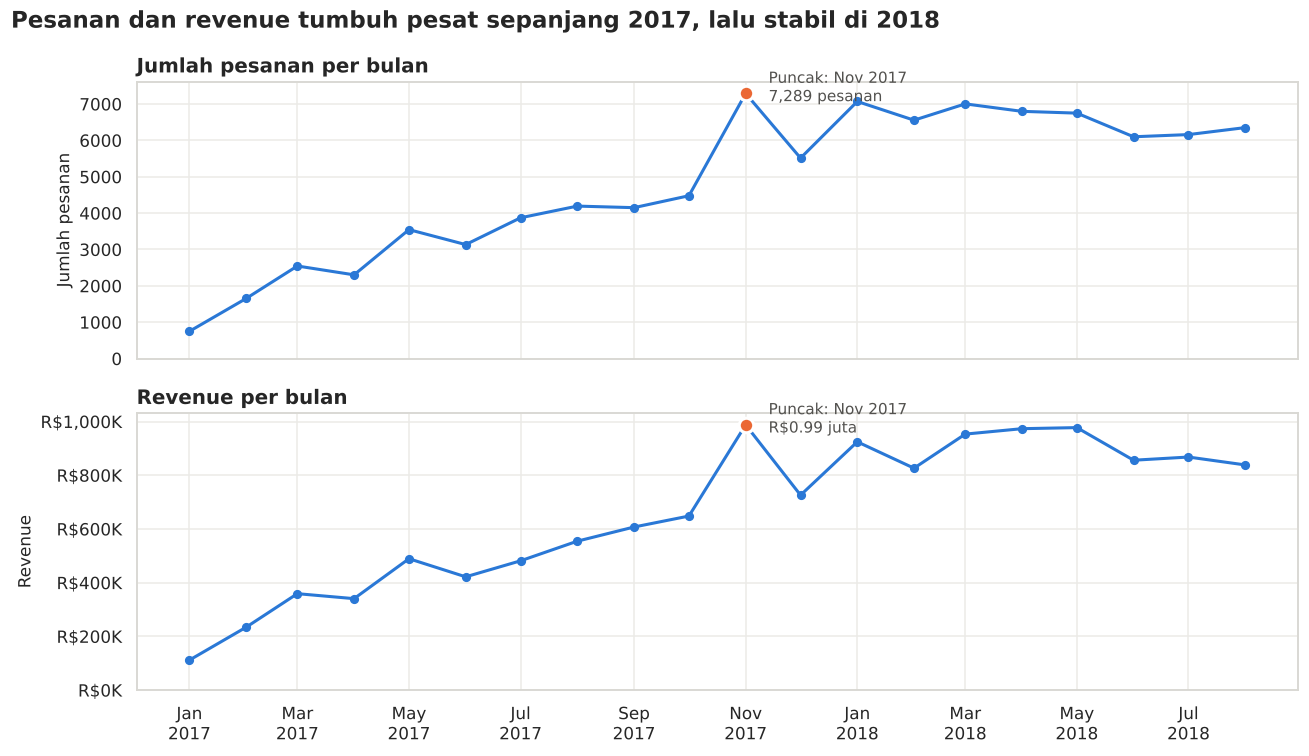

In [46]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
peak_idx = monthly_df["revenue"].idxmax()

for ax, col, title, ylabel in [
    (axes[0], "order_count", "Jumlah pesanan per bulan", "Jumlah pesanan"),
    (axes[1], "revenue", "Revenue per bulan", "Revenue"),
]:
    ax.plot(monthly_df["month"], monthly_df[col], color=MAIN, linewidth=2, marker="o", markersize=5)
    ax.scatter(monthly_df.loc[peak_idx, "month"], monthly_df.loc[peak_idx, col],
               s=90, color=ACCENT, zorder=5, edgecolor="white", linewidth=2)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)

axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_brl))
axes[0].annotate(f"Puncak: {monthly_df.loc[peak_idx, 'month']:%b %Y}\n"
                 f"{monthly_df.loc[peak_idx, 'order_count']:,} pesanan",
                 xy=(monthly_df.loc[peak_idx, "month"], monthly_df.loc[peak_idx, "order_count"]),
                 xytext=(15, -5), textcoords="offset points", color=TEXT, fontsize=10)
axes[1].annotate(f"Puncak: {monthly_df.loc[peak_idx, 'month']:%b %Y}\n"
                 f"R${monthly_df.loc[peak_idx, 'revenue'] / 1e6:,.2f} juta",
                 xy=(monthly_df.loc[peak_idx, "month"], monthly_df.loc[peak_idx, "revenue"]),
                 xytext=(15, -5), textcoords="offset points", color=TEXT, fontsize=10)
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
fig.suptitle("Pesanan dan revenue tumbuh pesat sepanjang 2017, lalu stabil di 2018",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

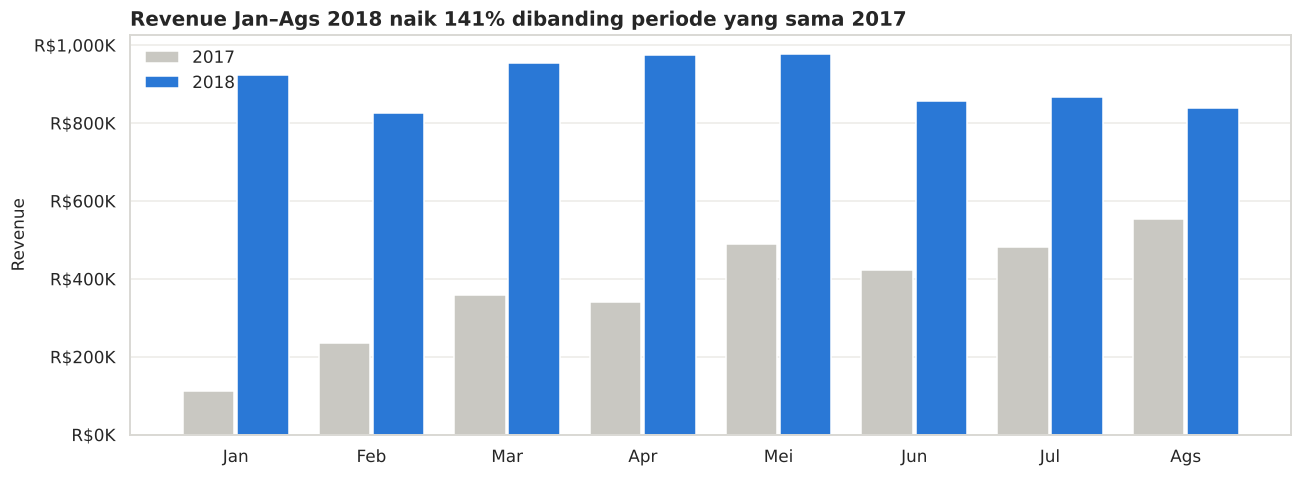

In [47]:
pivot = jan_aug.pivot(index="month_num", columns="year", values="revenue")
x = np.arange(len(pivot))
width = 0.38
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Ags"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - width / 2 - 0.01, pivot[2017], width, color=GREY, label="2017")
ax.bar(x + width / 2 + 0.01, pivot[2018], width, color=MAIN, label="2018")
ax.set_xticks(x)
ax.set_xticklabels(month_names)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_brl))
ax.set_ylabel("Revenue")
ax.set_title(f"Revenue Jan–Ags 2018 naik {yoy.loc['growth_%', 'revenue']:.0f}% dibanding periode yang sama 2017")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Insight:**
- Grafik garis menunjukkan dua fase: **pertumbuhan cepat** sepanjang 2017 dan **fase stabil** di 2018. Jumlah pesanan dan revenue bergerak hampir identik, sehingga pertumbuhan revenue terutama berasal dari bertambahnya jumlah pesanan, bukan dari kenaikan nilai per pesanan.
- Puncak revenue terjadi pada **November 2017** (R$987.765; 7.289 pesanan), lalu terkoreksi pada Desember. Pola ini menandakan efek kampanye Black Friday.
- Grafik batang membuktikan setiap bulan Jan–Ags 2018 lebih tinggi dari bulan yang sama di 2017, dengan total pertumbuhan revenue **141%**. Namun, kenaikan antarbulan di 2018 sudah melandai sehingga perlu pendorong pertumbuhan baru.

### Pertanyaan 2: Kategori produk apa saja yang termasuk 10 besar penyumbang revenue, berapa kontribusinya, dan kategori mana yang paling kecil?

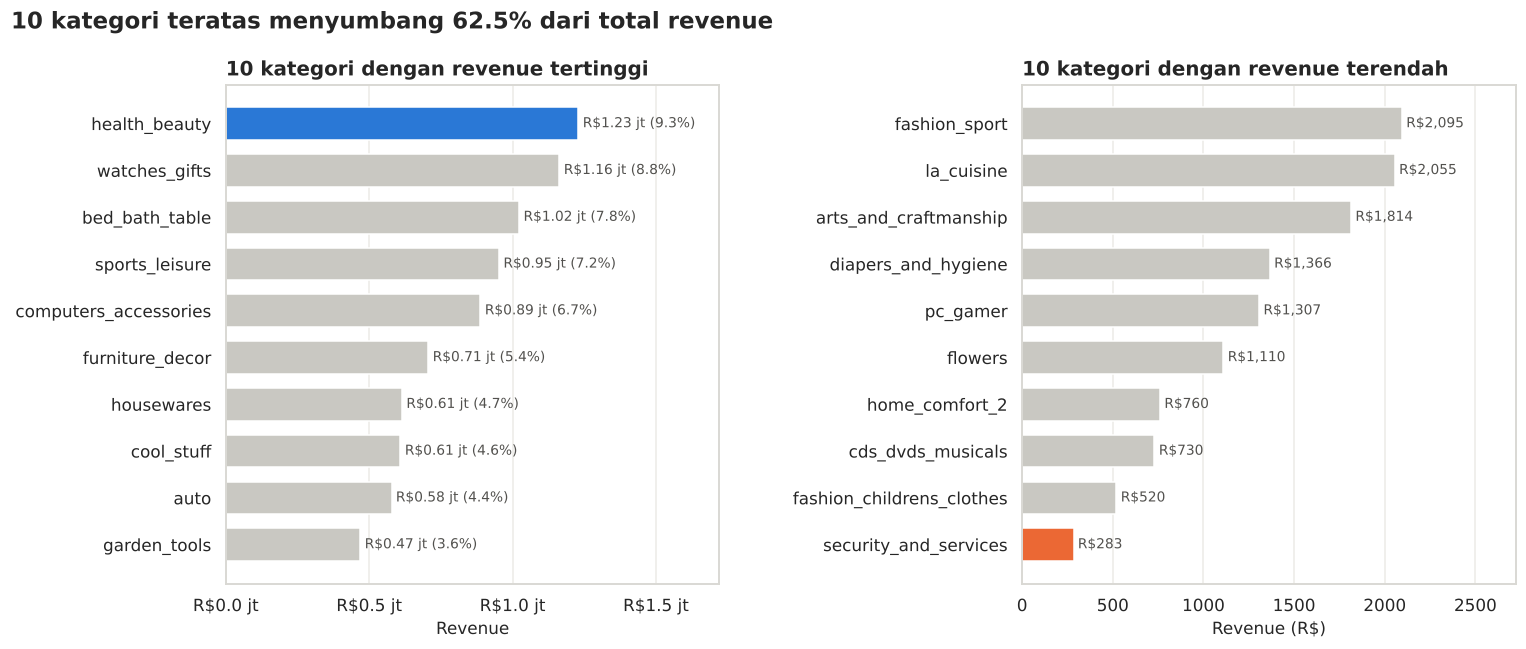

In [48]:
top10 = category_df.head(10).iloc[::-1]
bottom10 = category_df.tail(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors_top = [GREY] * 9 + [MAIN]          # kategori #1 ditekankan
axes[0].barh(top10["product_category_name_english"], top10["revenue"], color=colors_top, height=0.7)
for y, (rev, share) in enumerate(zip(top10["revenue"], top10["revenue_share_pct"])):
    axes[0].text(rev, y, f" R${rev / 1e6:.2f} jt ({share:.1f}%)", va="center", fontsize=9, color=TEXT)
axes[0].set_title("10 kategori dengan revenue tertinggi")
axes[0].set_xlabel("Revenue")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: f"R${x / 1e6:.1f} jt"))
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(4))
axes[0].set_xlim(0, top10["revenue"].max() * 1.4)
axes[0].grid(axis="y", visible=False)

colors_bottom = [ACCENT] + [GREY] * 9       # kategori terendah ditekankan
axes[1].barh(bottom10["product_category_name_english"], bottom10["revenue"], color=colors_bottom, height=0.7)
for y, rev in enumerate(bottom10["revenue"]):
    axes[1].text(rev, y, f" R${rev:,.0f}", va="center", fontsize=9, color=TEXT)
axes[1].set_title("10 kategori dengan revenue terendah")
axes[1].set_xlabel("Revenue (R$)")
axes[1].set_xlim(0, bottom10["revenue"].max() * 1.3)
axes[1].grid(axis="y", visible=False)

fig.suptitle(f"10 kategori teratas menyumbang {top10_share:.1f}% dari total revenue",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout(w_pad=4)
plt.show()

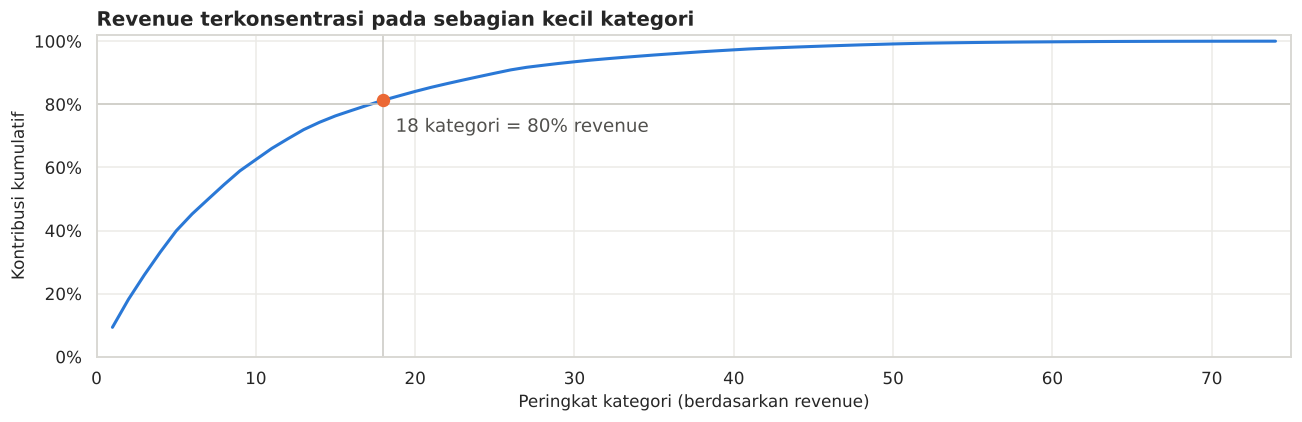

In [49]:
# Kurva Pareto: berapa banyak kategori yang dibutuhkan untuk mencapai 80% revenue
fig, ax = plt.subplots(figsize=(12, 4))
ranks = np.arange(1, len(category_df) + 1)
ax.plot(ranks, category_df["cumulative_share_pct"], color=MAIN, linewidth=2)
ax.axhline(80, color=GREY, linewidth=1)
ax.axvline(n_80, color=GREY, linewidth=1)
ax.scatter([n_80], [category_df.loc[n_80 - 1, "cumulative_share_pct"]], color=ACCENT, s=60, zorder=5)
ax.annotate(f"{n_80} kategori = 80% revenue", xy=(n_80, 80), xytext=(8, -18),
            textcoords="offset points", color=TEXT)
ax.set_xlabel("Peringkat kategori (berdasarkan revenue)")
ax.set_ylabel("Kontribusi kumulatif")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 102)
ax.set_xlim(0, len(category_df) + 1)
ax.set_title("Revenue terkonsentrasi pada sebagian kecil kategori")
plt.tight_layout()
plt.show()

**Insight:**
- `health_beauty`, `watches_gifts`, dan `bed_bath_table` adalah tiga penyumbang revenue terbesar; 10 kategori teratas menyumbang **62,5%** total revenue.
- Kurva Pareto menunjukkan revenue sangat terkonsentrasi: **18 dari 74 kategori** sudah mencakup 80% revenue, sedangkan 56 kategori lainnya hanya berbagi 20%.
- Kategori paling kecil, `security_and_services`, hanya menghasilkan R$283 dari 2 pesanan selama 20 bulan. Kategori di ekor bawah ini tidak layak mendapat anggaran promosi besar.

### Pertanyaan 3: Seberapa besar selisih review score antara pesanan terlambat dan tepat waktu, dan bagaimana skornya berubah menurut lama keterlambatan?

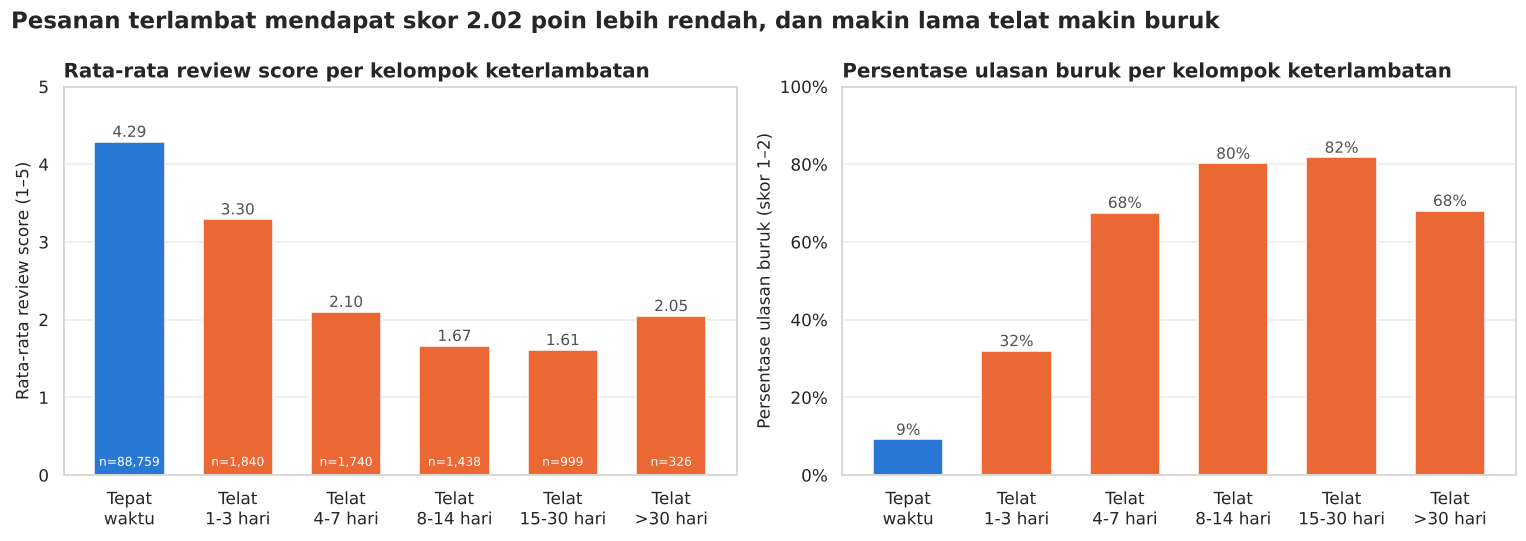

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bar_colors = [MAIN] + [ACCENT] * (len(delay_group_df) - 1)
labels = [lbl.replace(" ", "\n", 1) for lbl in delay_group_df.index.astype(str)]

axes[0].bar(labels, delay_group_df["avg_review"], color=bar_colors, width=0.65)
for i, (score, n) in enumerate(zip(delay_group_df["avg_review"], delay_group_df["order_count"])):
    axes[0].text(i, score + 0.06, f"{score:.2f}", ha="center", fontsize=10, color=TEXT)
    axes[0].text(i, 0.12, f"n={n:,}", ha="center", fontsize=8, color="white")
axes[0].set_ylim(0, 5)
axes[0].set_ylabel("Rata-rata review score (1–5)")
axes[0].set_title("Rata-rata review score per kelompok keterlambatan")
axes[0].grid(axis="x", visible=False)

axes[1].bar(labels, delay_group_df["bad_review_pct"], color=bar_colors, width=0.65)
for i, pct in enumerate(delay_group_df["bad_review_pct"]):
    axes[1].text(i, pct + 1.2, f"{pct:.0f}%", ha="center", fontsize=10, color=TEXT)
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylabel("Persentase ulasan buruk (skor 1–2)")
axes[1].set_title("Persentase ulasan buruk per kelompok keterlambatan")
axes[1].grid(axis="x", visible=False)

gap = late_summary.loc["Tepat waktu", "avg_review"] - late_summary.loc["Terlambat", "avg_review"]
fig.suptitle(f"Pesanan terlambat mendapat skor {gap:.2f} poin lebih rendah, dan makin lama telat makin buruk",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Pesanan terlambat mendapat rata-rata skor **2,27** dibandingkan **4,29** untuk pesanan tepat waktu (selisih 2,02 poin).
- Keterlambatan 1–3 hari saja sudah menurunkan skor rata-rata hampir 1 poin dan menaikkan porsi ulasan buruk dari 9% menjadi 32%. Pada keterlambatan 8–30 hari, sekitar 80% ulasan bernilai buruk.
- Artinya, ketepatan janji pengiriman merupakan faktor yang sangat menentukan kepuasan pelanggan.

## Analisis Lanjutan (Opsional)

### 1. RFM Analysis

RFM digunakan untuk mengelompokkan pelanggan berdasarkan perilaku belanjanya. Perhitungan memakai `customer_unique_id` (identitas pelanggan sebenarnya), bukan `customer_id` yang berbeda di setiap pesanan.
- **Recency**: jumlah hari sejak pembelian terakhir, dihitung terhadap tanggal acuan 1 September 2018 (sehari setelah akhir periode).
- **Frequency**: jumlah pesanan unik selama periode analisis.
- **Monetary**: total revenue (R$) dari pelanggan tersebut selama periode analisis.

In [51]:
reference_date = END_DATE.normalize() + pd.Timedelta(days=1)

rfm_df = (main_df
    .groupby("customer_unique_id", as_index=False)
    .agg(last_order=("order_purchase_timestamp", "max"),
         frequency=("order_id", "nunique"),
         monetary=("price", "sum")))
rfm_df["recency"] = (reference_date - rfm_df["last_order"]).dt.days
rfm_df[["recency", "frequency", "monetary"]].describe()

,recency,frequency,monetary
count,"93,104.00","93,104.00","93,104.00"
mean,238.24,1.03,141.57
std,150.95,0.21,215.76
min,2.00,1.00,0.85
25%,116.00,1.00,47.65
50%,220.00,1.00,89.70
75%,347.00,1.00,154.17
max,603.00,15.00,"13,440.00"


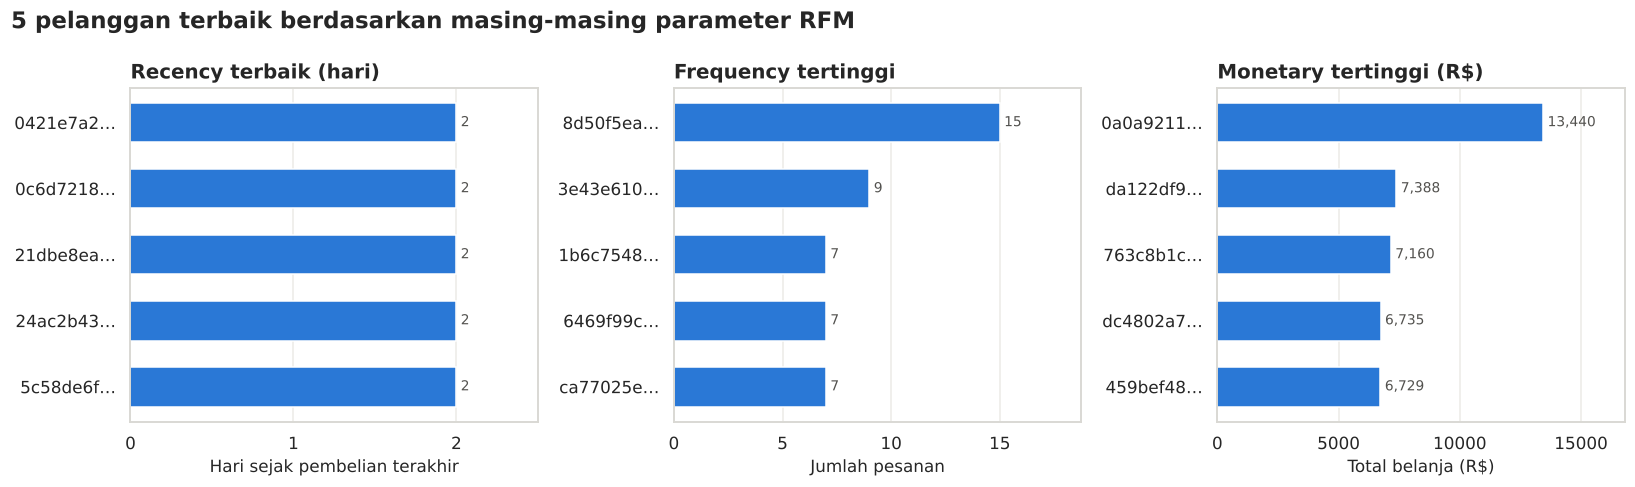

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
top_recency = rfm_df.nsmallest(5, "recency")
top_frequency = rfm_df.nlargest(5, "frequency")
top_monetary = rfm_df.nlargest(5, "monetary")

for ax, data, col, title, xlabel in [
    (axes[0], top_recency, "recency", "Recency terbaik (hari)", "Hari sejak pembelian terakhir"),
    (axes[1], top_frequency, "frequency", "Frequency tertinggi", "Jumlah pesanan"),
    (axes[2], top_monetary, "monetary", "Monetary tertinggi (R$)", "Total belanja (R$)"),
]:
    short_id = data["customer_unique_id"].str[:8] + "…"
    ax.barh(short_id.iloc[::-1], data[col].iloc[::-1], color=MAIN, height=0.6)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(4, integer=True))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(data[col].iloc[::-1]):
        ax.text(v, y, f" {v:,.0f}", va="center", fontsize=9, color=TEXT)
    ax.set_xlim(0, max(data[col].max() * 1.25, 1))

fig.suptitle("5 pelanggan terbaik berdasarkan masing-masing parameter RFM",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 2. Clustering dengan Manual Grouping (Segmentasi RFM)

Setiap parameter diberi skor tanpa algoritma machine learning:
- **R-score (1–5)**: binning berbasis kuantil (`pd.qcut`) pada recency, 5 = paling baru.
- **F-score (1–3)**: binning manual (`pd.cut`) karena sebagian besar pelanggan hanya belanja sekali: 1 pesanan → 1, 2 pesanan → 2, ≥3 pesanan → 3.
- **M-score (1–5)**: binning berbasis kuantil pada monetary, 5 = belanja terbesar.

Skor tersebut lalu dikelompokkan dengan **aturan bisnis** berikut:

| Segmen | Aturan | Makna |
|---|---|---|
| Champions | F ≥ 2 dan R ≥ 4 | Belanja berulang dan masih aktif |
| Loyal | F ≥ 2 dan R ≤ 3 | Pernah belanja berulang, mulai jarang |
| Baru – Nilai Tinggi | F = 1, R ≥ 4, M ≥ 4 | Baru belanja sekali dengan nilai besar |
| Baru | F = 1, R ≥ 4, M ≤ 3 | Baru belanja sekali, nilai kecil–sedang |
| Perlu Perhatian | F = 1, R = 3 | Sekali belanja, mulai lama tidak kembali |
| Berisiko – Nilai Tinggi | F = 1, R ≤ 2, M ≥ 4 | Pernah belanja besar, sudah lama hilang |
| Hibernating | F = 1, R ≤ 2, M ≤ 3 | Sekali belanja kecil, sudah lama hilang |

In [53]:
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = pd.cut(rfm_df["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 2, 3]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

conditions = [
    (rfm_df["f_score"] >= 2) & (rfm_df["r_score"] >= 4),
    (rfm_df["f_score"] >= 2),
    (rfm_df["r_score"] >= 4) & (rfm_df["m_score"] >= 4),
    (rfm_df["r_score"] >= 4),
    (rfm_df["r_score"] == 3),
    (rfm_df["m_score"] >= 4),
]
segments = ["Champions", "Loyal", "Baru – Nilai Tinggi", "Baru", "Perlu Perhatian", "Berisiko – Nilai Tinggi"]
rfm_df["segment"] = np.select(conditions, segments, default="Hibernating")

segment_order = segments + ["Hibernating"]
segment_df = (rfm_df
    .groupby("segment")
    .agg(customer_count=("customer_unique_id", "count"), revenue=("monetary", "sum"),
         avg_recency=("recency", "mean"), avg_monetary=("monetary", "mean"))
    .reindex(segment_order))
segment_df["customer_pct"] = segment_df["customer_count"] / segment_df["customer_count"].sum() * 100
segment_df["revenue_pct"] = segment_df["revenue"] / segment_df["revenue"].sum() * 100
segment_df

,customer_count,revenue,avg_recency,avg_monetary,customer_pct,revenue_pct
segment,,,,,,
Champions,1197,"324,211.48",89.97,270.85,1.29,2.46
Loyal,1592,"401,143.56",319.72,251.97,1.71,3.04
Baru – Nilai Tinggi,14405,"3,858,009.42",93.09,267.82,15.47,29.27
Baru,21717,"1,209,496.34",91.12,55.69,23.33,9.18
Perlu Perhatian,18048,"2,346,286.40",221.30,130.00,19.38,17.80
Berisiko – Nilai Tinggi,13606,"3,779,790.64",393.50,277.80,14.61,28.68
Hibernating,22539,"1,262,089.29",394.72,56.00,24.21,9.58


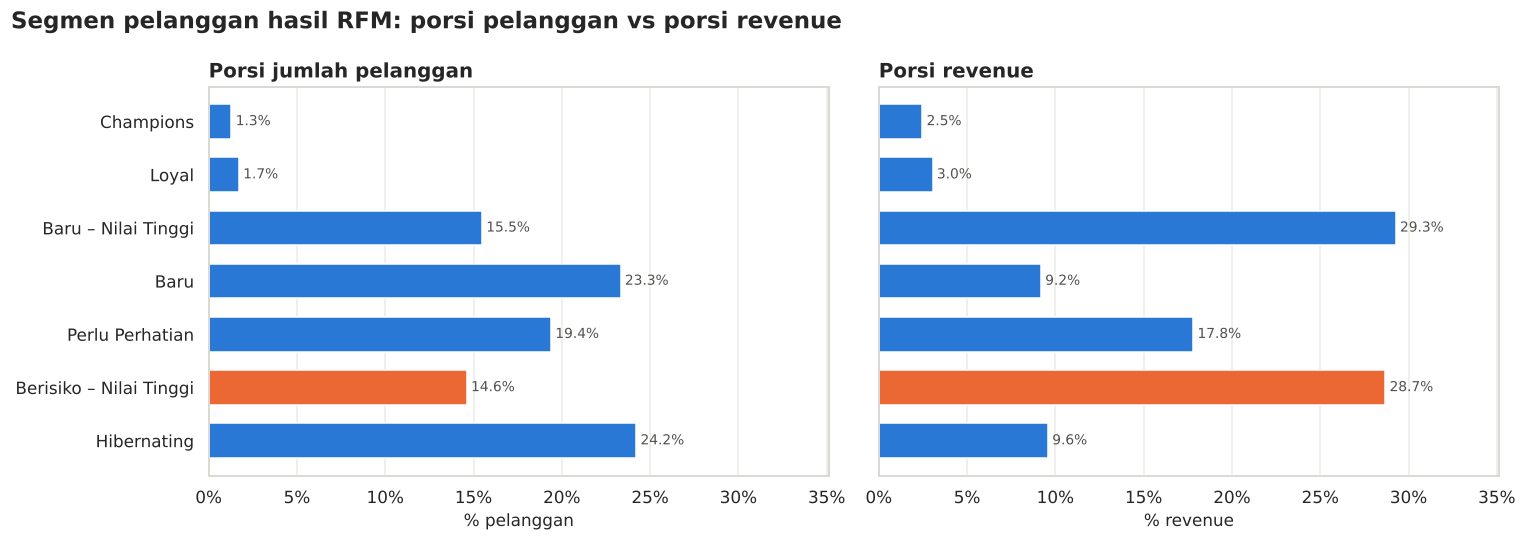

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_df = segment_df.iloc[::-1]
high_value = ["Berisiko – Nilai Tinggi"]
colors = [ACCENT if s in high_value else MAIN for s in plot_df.index]

axes[0].barh(plot_df.index, plot_df["customer_pct"], color=colors, height=0.65)
axes[0].set_title("Porsi jumlah pelanggan")
axes[0].set_xlabel("% pelanggan")
for y, v in enumerate(plot_df["customer_pct"]):
    axes[0].text(v, y, f" {v:.1f}%", va="center", fontsize=9, color=TEXT)

axes[1].barh(plot_df.index, plot_df["revenue_pct"], color=colors, height=0.65)
axes[1].set_title("Porsi revenue")
axes[1].set_xlabel("% revenue")
for y, v in enumerate(plot_df["revenue_pct"]):
    axes[1].text(v, y, f" {v:.1f}%", va="center", fontsize=9, color=TEXT)

for ax in axes:
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlim(0, max(segment_df["customer_pct"].max(), segment_df["revenue_pct"].max()) * 1.2)
    ax.grid(axis="y", visible=False)

fig.suptitle("Segmen pelanggan hasil RFM: porsi pelanggan vs porsi revenue",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Median recency 220 hari dan rata-rata frequency hanya 1,03 pesanan. Pelanggan dengan frekuensi tertinggi berbelanja 15 kali, dan pelanggan dengan nilai belanja tertinggi menghabiskan R$13.440.
- Segmen **Champions** dan **Loyal** (pelanggan yang belanja berulang) hanya 3,0% pelanggan dan 5,5% revenue, sejalan dengan rendahnya repeat order.
- Segmen **Berisiko – Nilai Tinggi** (ditandai oranye) hanya 14,6% pelanggan tetapi menyumbang **28,7% revenue**. Rata-rata mereka sudah 394 hari tidak berbelanja dengan nilai belanja R$278, sehingga merupakan target reaktivasi paling bernilai.
- Segmen **Baru – Nilai Tinggi** (15,5% pelanggan, 29,3% revenue) baru berbelanja sekali dalam ±3 bulan terakhir. Mereka adalah kandidat terbaik untuk didorong ke pembelian kedua.
- Segmen **Hibernating** mencakup 24,2% pelanggan tetapi hanya 9,6% revenue, sehingga menjadi prioritas terendah.

### 3. Geospatial Analysis

Peta dibuat dari batas wilayah state Brasil (GeoJSON) yang digambar dengan `matplotlib`, dan titik lokasi pelanggan dari tabel `geolocation` yang telah dibersihkan. Tujuannya melihat di wilayah mana pelanggan & revenue terkonsentrasi, serta apakah lama pengiriman berbeda antarwilayah.

In [55]:
if DATA_DIR.startswith("http"):
    with urlopen(DATA_DIR + "brazil_states.geojson") as f:
        brazil_geo = json.load(f)
else:
    with open(DATA_DIR + "brazil_states.geojson", encoding="utf-8") as f:
        brazil_geo = json.load(f)

def iter_polygons(feature):
    geom = feature["geometry"]
    return geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]

def polygon_centroid(ring):
    """Titik berat poligon (rumus shoelace) untuk posisi label state."""
    pts = np.array(ring)
    x, y = pts[:, 0], pts[:, 1]
    cross = x * np.roll(y, -1) - np.roll(x, -1) * y
    area = cross.sum() / 2
    return ((x + np.roll(x, -1)) * cross).sum() / (6 * area), ((y + np.roll(y, -1)) * cross).sum() / (6 * area)

def draw_states(ax, values=None, cmap="Blues", label="", log=False):
    """Menggambar peta state Brasil; jika values diberikan, warnai sebagai choropleth."""
    cm = plt.get_cmap(cmap)
    norm = None
    if values is not None:
        norm = (plt.matplotlib.colors.LogNorm(values.min(), values.max()) if log
                else plt.Normalize(values.min(), values.max()))
    for feat in brazil_geo["features"]:
        uf = feat["properties"]["sigla"]
        face = cm(norm(values[uf])) if values is not None and uf in values.index else "#f4f4f2"
        largest = max(iter_polygons(feat), key=lambda p: abs(np.ptp(np.array(p[0]), axis=0).prod()))
        for poly in iter_polygons(feat):
            ax.add_patch(Polygon(poly[0], closed=True, facecolor=face, edgecolor="white", linewidth=0.8))
        if values is not None:
            cx, cy = polygon_centroid(largest[0])
            txt_color = "white" if norm(values.get(uf, 0)) > 0.6 else "#0b0b0b"
            ax.text(cx, cy, uf, ha="center", va="center", fontsize=7, color=txt_color)
    ax.set_xlim(-75, -33)
    ax.set_ylim(-34.5, 6)
    ax.set_aspect("equal")
    ax.axis("off")
    if values is not None:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cm)
        cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.01)
        cbar.set_label(label)
        cbar.outline.set_visible(False)
        if log:
            cbar.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, pos: f"{v:g}"))

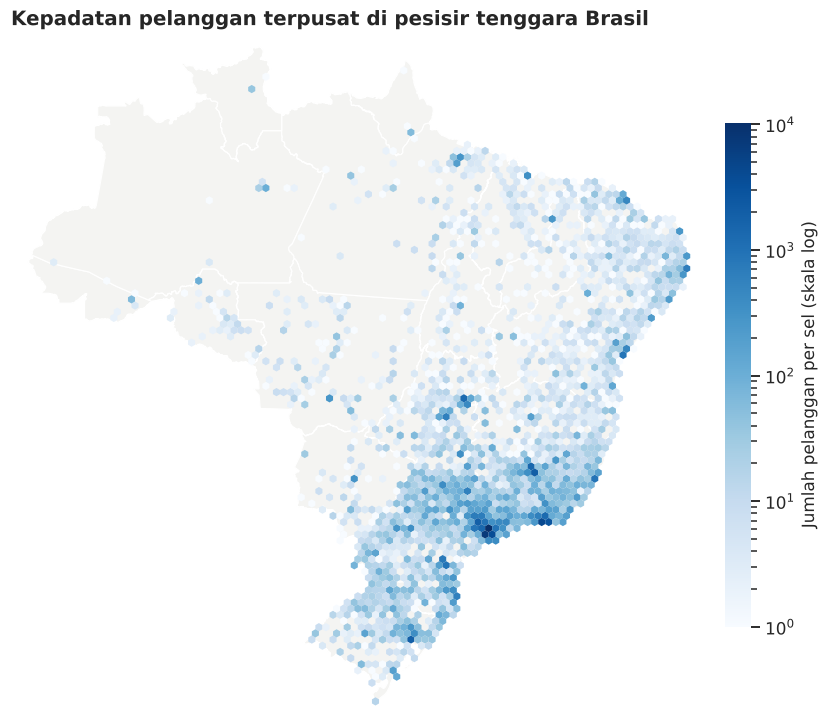

In [56]:
customer_points = main_df.drop_duplicates("customer_unique_id").dropna(subset=["customer_lat", "customer_lng"])

fig, ax = plt.subplots(figsize=(8, 8))
draw_states(ax)
hb = ax.hexbin(customer_points["customer_lng"], customer_points["customer_lat"],
               gridsize=90, bins="log", cmap="Blues", mincnt=1, linewidths=0, zorder=3)
cbar = plt.colorbar(hb, ax=ax, shrink=0.6, pad=0.01)
cbar.set_label("Jumlah pelanggan per sel (skala log)")
cbar.outline.set_visible(False)
ax.set_title("Kepadatan pelanggan terpusat di pesisir tenggara Brasil", loc="left")
plt.tight_layout()
plt.show()

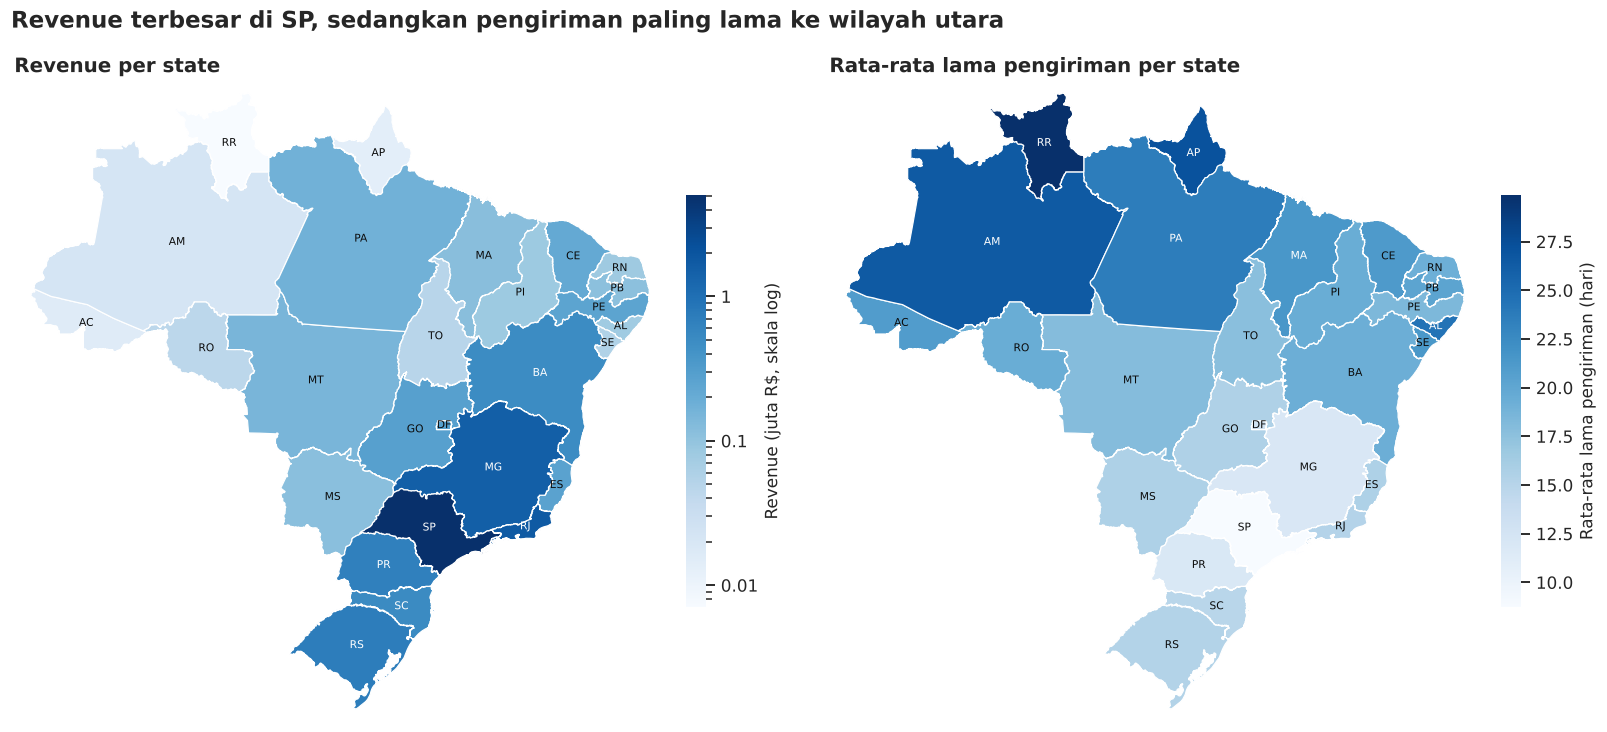

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw_states(axes[0], state_df["revenue"] / 1e6, label="Revenue (juta R$, skala log)", log=True)
axes[0].set_title("Revenue per state")
draw_states(axes[1], state_df["avg_delivery_days"], label="Rata-rata lama pengiriman (hari)")
axes[1].set_title("Rata-rata lama pengiriman per state")
fig.suptitle("Revenue terbesar di SP, sedangkan pengiriman paling lama ke wilayah utara",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [58]:
state_df[["customer_count", "revenue_share_pct", "avg_delivery_days", "late_pct", "avg_review"]].round(2)

,customer_count,revenue_share_pct,avg_delivery_days,late_pct,avg_review
customer_state,,,,,
SP,39065,38.36,8.71,4.43,4.25
RJ,11879,13.29,15.23,11.97,3.97
MG,10969,11.75,11.95,4.48,4.20
RS,5151,5.51,15.27,6.02,4.19
PR,4750,5.04,11.94,3.95,4.24
SC,3441,3.83,14.86,8.06,4.14
BA,3155,3.74,19.23,11.89,3.93
DF,2013,2.24,12.89,5.66,4.14
GO,1889,2.14,15.55,6.42,4.10


In [59]:
# Lokasi penjual sebagai konteks lama pengiriman
seller_share = sellers_df["seller_state"].value_counts(normalize=True).mul(100).round(1)
print("Porsi penjual per state (%):")
print(seller_share.head(5).to_string())

Porsi penjual per state (%):
seller_state
SP   59.70
PR   11.30
MG    7.90
SC    6.10
RJ    5.50


**Insight:**
- Peta kepadatan menunjukkan pelanggan terkonsentrasi di wilayah tenggara (SP, RJ, MG) dan selatan, sedangkan wilayah utara dan tengah-barat masih jarang. Ini sekaligus menunjukkan wilayah yang belum tergarap (*under-penetrated*).
- SP menyumbang 38,4% revenue; bersama RJ dan MG totalnya 63,4%.
- Lama pengiriman makin panjang ke arah utara: SP rata-rata 8,7 hari, sedangkan RR 29,9 hari, AP 27,1 hari, dan AM 26,5 hari. Hal ini wajar karena sekitar 60% penjual berada di SP.
- Wilayah utara (AM, AP) justru memiliki tingkat keterlambatan rendah (±3%) dan skor ulasan tinggi (4,24) meski pengirimannya lama, karena estimasinya realistis. Sebaliknya, AL (20,7%), MA (17,3%), dan SE (15,2%) paling sering terlambat dan skornya hanya 3,8–3,9. Ini menguatkan temuan Pertanyaan 3: **yang membuat pelanggan kecewa adalah janji yang meleset, bukan lamanya pengiriman.**

## Conclusion
- **Conclusion Pertanyaan 1:** Pesanan dan revenue tumbuh pesat selama 2017, dari 750 pesanan (R$112K) pada Januari menjadi puncak **7.289 pesanan (R$988K) pada November 2017** karena momen Black Friday. Pada 2018 penjualan stabil di kisaran R$826K–R$978K per bulan. Secara tahunan, revenue Jan–Ags 2018 (R$7,22 juta) **tumbuh 141%** dibanding Jan–Ags 2017 (R$2,99 juta), tetapi laju pertumbuhan bulanan di 2018 sudah melandai.
- **Conclusion Pertanyaan 2:** 10 besar kategori penyumbang revenue dipimpin oleh `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories`, dengan **kontribusi gabungan 62,5%**. Revenue sangat terkonsentrasi: 18 dari 74 kategori mencakup 80% revenue. Kategori dengan revenue paling kecil adalah `security_and_services` (R$283).
- **Conclusion Pertanyaan 3:** Pesanan terlambat (6,7% dari pesanan) mendapat rata-rata skor **2,27**, jauh di bawah **4,29** untuk pesanan tepat waktu (**selisih 2,02 poin**). Skor anjlok sejak keterlambatan 1–3 hari (3,30) dan mencapai titik terendah pada keterlambatan 8–30 hari (±1,6) dengan sekitar 80% ulasan buruk.
- **Conclusion Analisis Lanjutan:** 97% pelanggan hanya berbelanja sekali. Segmen *Berisiko – Nilai Tinggi* (14,6% pelanggan) menyimpan 28,7% revenue. Secara geografis, pasar terpusat di SP–RJ–MG (63,4% revenue), dan wilayah dengan janji pengiriman yang paling sering meleset (AL, MA, SE, RJ, BA) memiliki skor ulasan terendah.

### Rekomendasi Action Item
1. **Siapkan kampanye musiman sejak Oktober.** Tambah stok kategori teratas dan kapasitas logistik menjelang Black Friday, lalu lanjutkan dengan promo Desember untuk menahan penurunan 26% setelah puncak November.
2. **Fokuskan anggaran promosi dan stok pada 18 kategori penyumbang 80% revenue.** Gunakan strategi berbeda sesuai sumber revenue: *bundling* untuk kategori bervolume tinggi (`bed_bath_table`) dan promosi premium/cicilan untuk kategori berharga tinggi (`watches_gifts`). Kategori ekor bawah cukup dipertahankan tanpa promosi khusus.
3. **Jadikan ketepatan estimasi sebagai KPI logistik.** Tetapkan target keterlambatan di bawah 5%, prioritaskan perbaikan rute/mitra kurir ke RJ, BA, AL, MA, dan SE, kirim notifikasi proaktif plus voucher kompensasi saat pesanan berisiko telat, dan kalibrasi estimasi per wilayah seperti yang sudah berhasil di wilayah utara.
4. **Bangun program retensi berbasis segmen RFM.** Jalankan kampanye reaktivasi (voucher personal, rekomendasi produk) untuk segmen *Berisiko – Nilai Tinggi*, dan dorong pembelian kedua dalam 90 hari untuk segmen *Baru – Nilai Tinggi*, misalnya melalui poin loyalitas.